[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-1/blob/main/notebooks/ch24_LabCh24_FeedForward_Layers.ipynb)

**The Why Book of Deep Learning, Part 1** by Dr. Philemon Paul Daniel

**Chapter 24: Feed-Forward (MLP) Layers: The Quiet Half of Every Model** (Part V: Attending).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-1/read.html?ch=24](https://www.micyaai.com/books/why-deep-learning-1/read.html?ch=24)
* The simplified video course for kids that this book grew from: [aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)

Tested with TensorFlow 2.21 and Keras 3.14. In Colab: *Runtime > Run all*. A GPU runtime makes the bigger
models faster but none of them needs one.

---


# Lab Ch24 - Feed-Forward Layers
## The quiet half of every transformer: build it, count it, gate it, time it, and give it more room

This lab goes with **Chapter 24** of *The Why Book of Deep Learning*.

Inside every transformer block, after the tokens have talked to each other through attention, every token goes
on its own through a small two-layer network: `Dense(4d, relu)` then `Dense(d)`. It looks like an afterthought.
It holds about two thirds of the block's parameters. In this lab you build it, prove that it never mixes
positions, count it against attention, rebuild it in the gated SwiGLU form that modern language models use,
measure when it costs more than attention, and train a tiny model whose only job is to memorise facts while
you change how wide the feed-forward layer is.

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Build the position-wise feed-forward sub-layer and predict every shape | Steps 2 and 3 |
| Show that it treats every position separately, and that it *is* a 1×1 `Conv1D` | Steps 4 and 5 |
| Count 8d² + 5d by hand and compare it with attention's 4d² + 4d | Steps 6 to 8 |
| Build SwiGLU and explain the 8/3·d hidden-size rule | Steps 9 to 11 |
| Count multiply-adds for the MLP and for attention and find where they cross | Steps 12 to 14 |
| See how the expansion factor changes what a model can memorise | Steps 15 to 18 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**. A wrong prediction that you
understand afterwards is worth more than a right one you guessed.

> **Runtime:** about one to two minutes on a laptop CPU, plus the time to import TensorFlow. The training
> part uses a tiny model (width 32) and 4,000 made-up facts; nothing is downloaded.

---
# Part A - The sub-layer, shape by shape

---
## Step 1 - Imports and one seed

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(24)
np.set_printoptions(precision=4, suppress=True)
T0 = time.time()
print("TensorFlow:", tf.__version__, "  Keras:", keras.__version__)

TensorFlow: 2.21.0   Keras: 3.14.1


---
## Step 2 - The feed-forward sub-layer as a function

Two `Dense` layers. The first widens every token from d numbers to 4d and applies a non-linearity; the second
brings it back to d. A `Dense` layer in Keras always acts on the **last axis** of its input, so on a
`(batch, T, d)` tensor it is applied to each of the T token vectors with the same weights.

> **Predict:** the shape after the first `Dense` and after the second, for a batch of 2 sequences of 10 tokens
> at width d = 64.

In [2]:
def feed_forward(d, expansion=4, activation="relu", name="ffn"):
    """Position-wise feed-forward sub-layer: (batch, T, d) -> (batch, T, expansion*d) -> (batch, T, d)."""
    return keras.Sequential([
        layers.Input(shape=(None, d)),
        layers.Dense(expansion * d, activation=activation, name=f"{name}_up"),
        layers.Dense(d, name=f"{name}_down"),
    ], name=name)

d, T = 64, 10
ffn = feed_forward(d)
x = tf.random.normal((2, T, d))
h = ffn.get_layer("ffn_up")(x)
y = ffn(x)
print("input      ", x.shape)
print("hidden     ", h.shape, "  <- the only wide arrow")
print("output     ", y.shape)

input       (2, 10, 64)
hidden      (2, 10, 256)   <- the only wide arrow
output      (2, 10, 64)


### Why we see this

`(2, 10, 64)` goes in, `(2, 10, 256)` sits in the middle, `(2, 10, 64)` comes out. The output has exactly the
shape of the input, which is what lets it be added back onto the residual stream (Chapter 23). The T axis is
never touched: nothing in either `Dense` layer even knows how long the sequence is. That is why the input
shape is `(None, d)`: the same layer serves 10 tokens or 10,000.

---
## Step 3 - Weight shapes

> **Predict:** the shapes of the two kernels and the two bias vectors. Does T appear anywhere?

In [3]:
for w in ffn.weights:
    print(f"{w.path:<22s} {str(tuple(w.shape)):<12s} {int(np.prod(w.shape)):>7,} numbers")
print("total:", f"{ffn.count_params():,}")

ffn/ffn_up/kernel      (64, 256)     16,384 numbers
ffn/ffn_up/bias        (256,)           256 numbers
ffn/ffn_down/kernel    (256, 64)     16,384 numbers
ffn/ffn_down/bias      (64,)             64 numbers
total: 33,088


---
## Step 4 - It never mixes positions

Change one token (position 3) and run the layer again. Attention would let that change leak into every
position. A position-wise layer should change row 3 and nothing else.

> **Predict:** which output rows change, and by how much do the others move?

In [4]:
x2 = x.numpy().copy()
x2[:, 3, :] += 5.0 * np.random.default_rng(1).normal(size=(2, d))   # disturb token 3 only
diff = np.abs(ffn(x2).numpy() - y.numpy()).max(axis=-1)              # largest change in each row
print("largest change per position (sequence 0):")
print(diff[0])
assert np.all(diff[:, [0, 1, 2, 4, 5, 6, 7, 8, 9]] == 0.0) and np.all(diff[:, 3] > 0)
print("Only position 3 moved. Every other row is bit-for-bit identical.")

largest change per position (sequence 0):
[0.     0.     0.     5.3937 0.     0.     0.     0.     0.     0.    ]
Only position 3 moved. Every other row is bit-for-bit identical.


### Why we see this

The other nine rows are not "almost" the same, they are **exactly** the same, to the last bit. The layer
computes each token from that token alone. So inside a transformer the division of labour is strict:
attention is the only place where information moves *between* positions; the feed-forward layer transforms
what is already *at* a position. A model with the attention removed is a bag of independent per-token
networks.

---
## Step 5 - The same layer is a 1×1 convolution

A `Conv1D` with `kernel_size=1` slides a window one token wide along the sequence, with the same weights at
every position: exactly what we just described. The 2017 paper says this in one sentence. Let us prove it by
copying the weights across.

A `Dense` kernel has shape `(d, 4d)`; a `Conv1D` kernel of width 1 has shape `(1, d, 4d)`. Only a new axis of
length 1 is needed.

> **Predict:** how big will the largest difference between the two outputs be?

In [5]:
conv = keras.Sequential([
    layers.Input(shape=(None, d)),
    layers.Conv1D(4 * d, kernel_size=1, activation="relu", name="conv_up"),
    layers.Conv1D(d, kernel_size=1, name="conv_down"),
], name="ffn_as_conv")

W1, b1 = ffn.get_layer("ffn_up").get_weights()
W2, b2 = ffn.get_layer("ffn_down").get_weights()
conv.get_layer("conv_up").set_weights([W1[np.newaxis], b1])       # (d, 4d) -> (1, d, 4d)
conv.get_layer("conv_down").set_weights([W2[np.newaxis], b2])
print("Dense kernel", W1.shape, "->  Conv1D kernel", conv.get_layer("conv_up").kernel.shape)
gap = np.abs(conv(x).numpy() - y.numpy()).max()
print(f"largest difference between Dense and Conv1D outputs: {gap:.2e}")
assert gap < 1e-4 and conv.count_params() == ffn.count_params()

Dense kernel (64, 256) ->  Conv1D kernel (1, 64, 256)
largest difference between Dense and Conv1D outputs: 4.77e-07


### Why we see this

The difference is zero or a rounding error of order 1e-6 (the two layers may add their products in a
different order). Same weights, same numbers. Remember this the next time you read a CNN paper: a
"1×1 convolution" (Chapter 15) mixes channels at each pixel without looking at the neighbours, which is the
same job the feed-forward layer does for each token.

---
# Part B - Counting: the two-thirds fact

---
## Step 6 - Count it by hand

* First `Dense`: d × 4d weights + 4d biases.
* Second `Dense`: 4d × d weights + d biases.
* Total: 8d² + 5d.

> **Predict:** the count at d = 64, then at d = 512.

In [6]:
def ffn_params(d, expansion=4, bias=True):
    h = expansion * d
    return 2 * d * h + (h + d if bias else 0)

def attn_params(d):
    return 4 * (d * d + d)          # query, key, value and output projections, each d x d + d

assert ffn.count_params() == ffn_params(64) == 8 * 64**2 + 5 * 64
print(f"d = 64 : feed-forward {ffn_params(64):,}  (Keras says {ffn.count_params():,})")

d = 512
ffn512 = feed_forward(d)
mha512 = layers.MultiHeadAttention(num_heads=8, key_dim=d // 8)
xs = tf.zeros((1, 4, d))
_ = mha512(xs, xs)                  # build it so it has weights
print(f"d = 512: feed-forward {ffn512.count_params():,}   attention {mha512.count_params():,}")
assert ffn512.count_params() == 8 * d * d + 5 * d == 2_099_712
assert mha512.count_params() == 4 * d * d + 4 * d == 1_050_624

d = 64 : feed-forward 33,088  (Keras says 33,088)


d = 512: feed-forward 2,099,712   attention 1,050,624


---
## Step 7 - The split

Add the two LayerNorms of a block (2 × 2d) and look at the shares.

> **Predict:** the feed-forward share of the whole block, to the nearest percent.

In [7]:
norms = 2 * 2 * d
block = ffn_params(d) + attn_params(d) + norms
print(f"feed-forward {ffn_params(d):>10,}   {ffn_params(d) / block:6.1%}")
print(f"attention    {attn_params(d):>10,}   {attn_params(d) / block:6.1%}")
print(f"LayerNorms   {norms:>10,}   {norms / block:6.1%}")
print(f"block        {block:>10,}")
assert block == 3_152_384
print(f"\nfeed-forward / (feed-forward + attention) = {ffn_params(d) / (ffn_params(d) + attn_params(d)):.4f}")

feed-forward  2,099,712    66.6%
attention     1,050,624    33.3%
LayerNorms        2,048     0.1%
block         3,152,384

feed-forward / (feed-forward + attention) = 0.6665


### Why we see this

Two thirds, almost exactly: 66.6% of the block. The reason is plain arithmetic. Attention has four d × d
matrices; the feed-forward layer has two d × 4d matrices, which is eight d × d matrices' worth. Eight against
four is two to one, whatever d is. The biases and norms are so small at d = 512 that they barely move the
split.

---
## Step 8 - Does the split depend on d? On the expansion factor?

> **Predict:** the feed-forward share at d = 64 and at d = 4,096 with expansion 4. Then the share at d = 512
> with expansion 1, 2 and 8.

In [8]:
print("expansion 4, different widths:")
for dd in [64, 512, 768, 4096]:
    f, a = ffn_params(dd), attn_params(dd)
    print(f"  d = {dd:>5}: ffn {f:>12,}  attn {a:>12,}  ffn share {f / (f + a):.4f}")
print("d = 512, different expansion factors:")
for r in [1, 2, 4, 8]:
    f, a = ffn_params(512, r), attn_params(512)
    print(f"  r = {r}: ffn {f:>10,}  ffn share {f / (f + a):.3f}   (2r / (2r + 4) = {2 * r / (2 * r + 4):.3f})")

expansion 4, different widths:
  d =    64: ffn       33,088  attn       16,640  ffn share 0.6654
  d =   512: ffn    2,099,712  attn    1,050,624  ffn share 0.6665
  d =   768: ffn    4,722,432  attn    2,362,368  ffn share 0.6666
  d =  4096: ffn  134,238,208  attn   67,125,248  ffn share 0.6666
d = 512, different expansion factors:
  r = 1: ffn    525,312  ffn share 0.333   (2r / (2r + 4) = 0.333)
  r = 2: ffn  1,050,112  ffn share 0.500   (2r / (2r + 4) = 0.500)
  r = 4: ffn  2,099,712  ffn share 0.667   (2r / (2r + 4) = 0.667)
  r = 8: ffn  4,198,912  ffn share 0.800   (2r / (2r + 4) = 0.800)


### Why we see this

The share is fixed by the expansion factor r, not by the width: the feed-forward layer has 2r d × d matrices'
worth of weights against attention's 4, so its share is 2r / (2r + 4). At r = 4 that is 8/12 = 2/3; at r = 1 it
is one third; at r = 8 it is four fifths. When you prune or quantise a transformer, this is where most of the
bytes are.

---
# Part C - SwiGLU: the gated version modern LLMs use

---
## Step 9 - Build a SwiGLU feed-forward layer

A **gated** feed-forward layer computes two wide projections of the token instead of one. One goes through a
smooth activation (SiLU, also called Swish: x · sigmoid(x)) and acts as a **gate**; the other is left linear.
They are multiplied number by number, and a third matrix brings the result back to d.

```
token (d) ──► Dense(h, silu) ──┐
          └─► Dense(h) ────────┴─► multiply ──► Dense(d) ──► out (d)
```

Three matrices instead of two, and LLaMA-style models leave out every bias.

> **Predict:** with h = 4d, how many parameters does it have at d = 512, compared with the plain layer?

In [9]:
def swiglu(d, hidden, name="swiglu"):
    inp = layers.Input(shape=(None, d))
    gate = layers.Dense(hidden, activation="silu", use_bias=False, name=f"{name}_gate")(inp)
    up = layers.Dense(hidden, use_bias=False, name=f"{name}_up")(inp)
    out = layers.Dense(d, use_bias=False, name=f"{name}_down")(layers.Multiply()([gate, up]))
    return keras.Model(inp, out, name=name)

d = 512
naive = swiglu(d, 4 * d, name="swiglu_4d")
plain_nobias = ffn_params(d, bias=False)
print(f"plain ReLU FFN, no biases     : {plain_nobias:>10,}   (8d²)")
print(f"SwiGLU with hidden = 4d = {4*d}: {naive.count_params():>10,}   ({naive.count_params() / plain_nobias:.2f}x)")
assert naive.count_params() == 3 * d * 4 * d

plain ReLU FFN, no biases     :  2,097,152   (8d²)
SwiGLU with hidden = 4d = 2048:  3,145,728   (1.50x)


### Why we see this

Three d × 4d matrices are 12d² against the plain layer's 8d²: **50% more** parameters (and 50% more
multiply-adds per token). This is the trap the chapter warns about: copy the hidden size of the plain layer
into a gated layer and the model silently grows by half.

---
## Step 10 - The 8/3·d rule

To keep the budget, shrink the hidden size so that 3·d·h = 8d², which gives h = 8d / 3. At d = 512 that is
1,365.3, so we round down to 1,365. (Real models round to a convenient multiple: LLaMA's 4,096-wide model uses
11,008, which is 2.69 × d.)

> **Predict:** the SwiGLU count with h = 1,365, and how close it is to the plain layer.

In [10]:
h_rule = int(8 * d / 3)
balanced = swiglu(d, h_rule, name="swiglu_83")
print(f"hidden = int(8d/3) = {h_rule}")
print(f"SwiGLU (no biases)       : {balanced.count_params():>10,}")
print(f"plain ReLU FFN (no bias) : {plain_nobias:>10,}")
print(f"plain ReLU FFN (biases)  : {ffn_params(d):>10,}")
ratio = balanced.count_params() / ffn_params(d)
print(f"SwiGLU / plain-with-biases = {ratio:.4f}")
assert abs(ratio - 1) < 0.01
print(f"LLaMA-7B check: 11008 / 4096 = {11008 / 4096:.3f}   8/3 = {8 / 3:.3f}")

hidden = int(8d/3) = 1365


SwiGLU (no biases)       :  2,096,640
plain ReLU FFN (no bias) :  2,097,152
plain ReLU FFN (biases)  :  2,099,712
SwiGLU / plain-with-biases = 0.9985
LLaMA-7B check: 11008 / 4096 = 2.688   8/3 = 2.667


---
## Step 11 - Same shape in, same shape out

> **Predict:** the output shape of the SwiGLU layer on a `(2, 10, 512)` batch.

In [11]:
xb = tf.random.normal((2, 10, d))
print("plain :", ffn512(xb).shape)
print("SwiGLU:", balanced(xb).shape)
for w in balanced.weights:
    print(f"  {w.path:<20s} {tuple(w.shape)}")

plain : (2, 10, 512)
SwiGLU: (2, 10, 512)
  swiglu_83_gate/kernel (512, 1365)
  swiglu_83_up/kernel  (512, 1365)
  swiglu_83_down/kernel (1365, 512)


### Why we see this

From the outside the two layers are interchangeable: `(batch, T, d)` in and out, position-wise, the same
parameter budget. Inside, the gated version lets one projection decide, per hidden unit and per token, how
much of the other to let through: a multiplication instead of a fixed threshold. Experiments in 2020 found it
gives a small but consistent quality gain at the same cost, which is why most recent open language models
use it.

---
# Part D - Who costs more: the MLP or attention?

---
## Step 12 - Count the multiply-adds

For one sequence of T tokens at width d, in one block:

* **Feed-forward:** every token does d × 4d, then 4d × d multiply-adds: **8·T·d²**.
* **Attention:** the four projections cost **4·T·d²**; the score table Q·Kᵀ costs T·T·d, and blending the
  values costs another T·T·d: **2·T²·d**.

> **Predict:** at what T are the two equal? (Set 8Td² = 4Td² + 2T²d and solve.)

In [12]:
def macs_ffn(T, d, r=4):
    return 2 * r * T * d * d

def macs_attn(T, d):
    return 4 * T * d * d + 2 * T * T * d

d = 512
print(f"{'T':>6} {'FFN (M)':>10} {'attention (M)':>14} {'FFN / attn':>11}")
for T in [128, 256, 512, 1024, 2048, 4096, 8192]:
    f, a = macs_ffn(T, d), macs_attn(T, d)
    print(f"{T:>6} {f / 1e6:>10,.0f} {a / 1e6:>14,.0f} {f / a:>11.2f}")
cross = next(T for T in range(1, 100_000) if macs_attn(T, d) >= macs_ffn(T, d))
print(f"\nfirst T where attention costs at least as much as the MLP: {cross}  (2d = {2 * d})")
assert cross == 2 * d

     T    FFN (M)  attention (M)  FFN / attn
   128        268            151        1.78
   256        537            336        1.60
   512      1,074            805        1.33
  1024      2,147          2,147        1.00
  2048      4,295          6,442        0.67
  4096      8,590         21,475        0.40
  8192     17,180         77,309        0.22

first T where attention costs at least as much as the MLP: 1024  (2d = 1024)


### Why we see this

They cross at **T = 2d**: 1,024 tokens at d = 512. Below that the feed-forward layer is the bigger bill; above
it attention's T² term takes over and keeps growing. (At T = 2d something neat happens: attention's two halves,
projections and T × T products, are also equal to each other.) The T² part *alone* overtakes the MLP at
T = 4d. Short prompts, chat turns and most classification inputs live on the left of the crossover, where the
MLP is the main cost. Book-length contexts live far to the right.

---
## Step 13 - Draw the two curves

> **Predict:** the shape of each curve on ordinary (linear) axes.

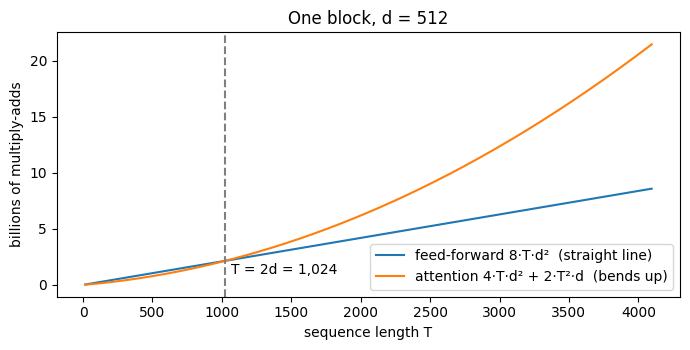

In [13]:
Ts = np.arange(16, 4097, 16)
plt.figure(figsize=(7, 3.6))
plt.plot(Ts, macs_ffn(Ts, d) / 1e9, label="feed-forward 8·T·d²  (straight line)")
plt.plot(Ts, macs_attn(Ts, d) / 1e9, label="attention 4·T·d² + 2·T²·d  (bends up)")
plt.axvline(2 * d, ls="--", c="grey"); plt.text(2 * d + 40, 1, "T = 2d = 1,024")
plt.xlabel("sequence length T"); plt.ylabel("billions of multiply-adds"); plt.title("One block, d = 512")
plt.legend(); plt.tight_layout(); plt.show()

---
## Step 14 - Time them on your CPU

Counting is theory; let us time real Keras layers. We use d = 256 (theory says they cross at T = 512) and a
batch of 4. Each layer is wrapped in `tf.function` and run several times after a warm-up.

> **Predict:** will the measured crossover be exactly at T = 512? Earlier or later?

In [14]:
d = 256
ffn_t = feed_forward(d, name="ffn_t")
mha_t = layers.MultiHeadAttention(num_heads=4, key_dim=d // 4)
@tf.function(reduce_retracing=True)
def run_ffn(z):
    return ffn_t(z)

@tf.function(reduce_retracing=True)
def run_mha(z):
    return mha_t(z, z)          # self-attention: queries, keys and values from the same tokens

def ms(fn, z, reps=8):
    fn(z)                                            # warm-up (and tracing)
    t = time.perf_counter()
    for _ in range(reps):
        fn(z)
    return (time.perf_counter() - t) / reps * 1000

rows = []
for T in [32, 64, 128, 256, 512, 1024]:
    z = tf.random.normal((4, T, d))
    rows.append((T, ms(run_ffn, z), ms(run_mha, z)))
    print(f"T = {T:>5}: feed-forward {rows[-1][1]:7.2f} ms   attention {rows[-1][2]:7.2f} ms")
later = [T for T, f, a in rows if a > f * 1.2]
print("\nattention clearly slower (by 20%+) from T =", later[0] if later else "never in this range")

T =    32: feed-forward    1.27 ms   attention    1.43 ms
T =    64: feed-forward    1.53 ms   attention    1.53 ms
T =   128: feed-forward    2.49 ms   attention    2.24 ms
T =   256: feed-forward    3.85 ms   attention    3.93 ms


T =   512: feed-forward    7.07 ms   attention   11.50 ms


T =  1024: feed-forward   14.52 ms   attention   37.06 ms

attention clearly slower (by 20%+) from T = 512


### Why we see this

Your numbers depend on your machine, but the pattern is reliable: the feed-forward time grows in a straight
line, the attention time bends upwards, and the measured crossover sits near the counted one (often a little
earlier). Multiply-adds are not the whole story: attention also computes a softmax over T × T numbers and
shuffles heads around in memory, work that counting multiply-adds ignores. On a GPU, with fused kernels such
as FlashAttention (Chapter 25), the picture shifts again. **Count first, then measure on the hardware you will
really use.**

---
# Part E - The expansion factor: room to remember

---
## Step 15 - A task that is pure memory

Make up 4,000 "facts": 400 subjects × 10 relations, each pair mapped to one of 100 objects **at random**.
("Subject 17, relation 3 → object 58.") There is no pattern to find, so the only way to score well is to store
the table somewhere in the weights. Each example is a sequence of two tokens, `[subject, relation]`, and the
model must name the object.

We measure training accuracy on purpose: the question is how much a model can *hold*, not how well it
generalises (random facts cannot be generalised).

> **Predict:** what accuracy would a model that has learnt nothing get?

In [15]:
rng = np.random.default_rng(24)
N_SUBJ, N_REL, N_OBJ = 400, 10, 100
subj = np.repeat(np.arange(N_SUBJ), N_REL)
rel = np.tile(np.arange(N_REL), N_SUBJ) + N_SUBJ            # relation tokens come after subject tokens
X = np.stack([subj, rel], axis=1).astype("int32")
Y = rng.integers(0, N_OBJ, size=len(X))
print("inputs", X.shape, " targets", Y.shape, " example:", X[171], "->", Y[171])
print(f"chance accuracy: 1/{N_OBJ} = {1 / N_OBJ:.0%}")

inputs (4000, 2)  targets (4000,)  example: [ 17 401] -> 11
chance accuracy: 1/100 = 1%


---
## Step 16 - One tiny transformer block, expansion factor r

Width d = 32. Token embedding + a learnt position embedding, one pre-norm block (2-head attention, then the
feed-forward layer with hidden size r·d), a final norm, and a `Dense(100)` read-out from the last position.
Only r changes between runs.

> **Predict:** the feed-forward parameter count for r = 1 and r = 8 (use 8d² + 5d with 4 replaced by r).

In [16]:
D = 32

def memoriser(r, d=D):
    inp = layers.Input(shape=(2,), dtype="int32")
    tok = layers.Embedding(N_SUBJ + N_REL, d, name="tokens")(inp)
    pos = layers.Embedding(2, d, name="positions")(keras.ops.arange(2))
    x = tok + pos
    h = layers.LayerNormalization(name="ln1")(x)
    x = x + layers.MultiHeadAttention(num_heads=2, key_dim=d // 2, name="mha")(h, h)
    h = layers.LayerNormalization(name="ln2")(x)
    h = layers.Dense(r * d, activation="relu", name="ff_up")(h)
    x = x + layers.Dense(d, name="ff_down")(h)
    x = layers.LayerNormalization(name="ln_final")(x)
    out = layers.Dense(N_OBJ, name="readout")(x[:, -1])
    return keras.Model(inp, out, name=f"memoriser_r{r}")

for r in [1, 8]:
    m = memoriser(r)
    f = m.get_layer("ff_up").count_params() + m.get_layer("ff_down").count_params()
    assert f == 2 * r * D * D + r * D + D
    print(f"r = {r}: whole model {m.count_params():>6,}   feed-forward {f:>6,}")

r = 1: whole model 22,948   feed-forward  2,112
r = 8: whole model 37,508   feed-forward 16,672


---
## Step 17 - Train r = 1, 2, 4 and 8

Same seed, same data, same 40 epochs, batch 64, Adam at 0.003. About ten seconds each on a laptop CPU.

> **Predict:** order the four final accuracies. Will doubling r always help? By a constant amount?

In [17]:
results = {}
for r in [1, 2, 4, 8]:
    keras.utils.set_random_seed(24)
    m = memoriser(r)
    m.compile(optimizer=keras.optimizers.Adam(3e-3),
              loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])
    t = time.time()
    hist = m.fit(X, Y, epochs=40, batch_size=64, verbose=0)
    results[r] = (m, hist.history["accuracy"])
    f = 2 * r * D * D + r * D + D
    print(f"r = {r}: ffn params {f:>6,}   final train accuracy {hist.history['accuracy'][-1]:.3f}"
          f"   ({time.time() - t:.0f} s)")

r = 1: ffn params  2,112   final train accuracy 0.565   (10 s)


r = 2: ffn params  4,192   final train accuracy 0.664   (10 s)


r = 4: ffn params  8,352   final train accuracy 0.766   (11 s)


r = 8: ffn params 16,672   final train accuracy 0.839   (11 s)


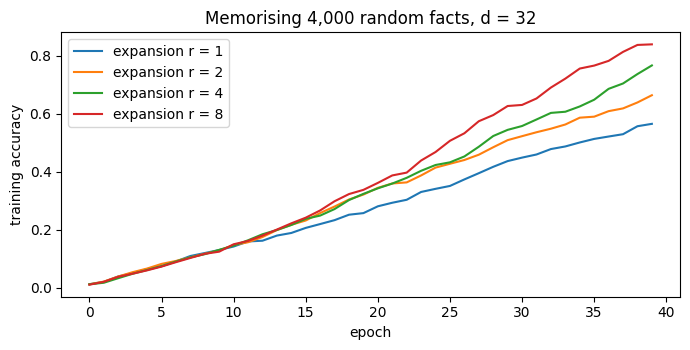

In [18]:
plt.figure(figsize=(7, 3.6))
for r, (_, acc) in results.items():
    plt.plot(acc, label=f"expansion r = {r}")
plt.xlabel("epoch"); plt.ylabel("training accuracy"); plt.title("Memorising 4,000 random facts, d = 32")
plt.legend(); plt.tight_layout(); plt.show()

### Why we see this

With the same attention, the same embeddings and the same read-out, the wider feed-forward layer stores more
of the table in the same 40 epochs: accuracy rises with r, with diminishing steps. (On this machine the
author's run gave about 56%, 66%, 77% and 84% for r = 1, 2, 4 and 8; your figures may differ by a few points.)
This is a toy, but it shows the property the chapter describes: the feed-forward layer is where a transformer
has room to keep things. It is also a reminder that "wider" buys capacity, not wisdom: none of these models
can answer a fact it has not seen.

---
## Step 18 - Most hidden units are silent for any one token

The key-value picture says each hidden unit is a detector that fires for some inputs and stays at zero for
the rest. Let us look at the r = 8 model's 256 hidden ReLU units on all 4,000 examples.

> **Predict:** what fraction of the 256 units is non-zero for a typical example?

hidden units: 256
fraction active per example: mean 0.23, min 0.05, max 0.50
units that never fire on any example: 0


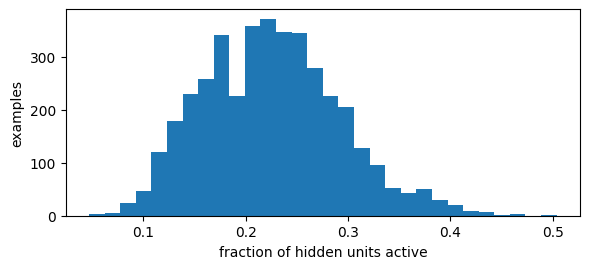

In [19]:
m8 = results[8][0]
probe = keras.Model(m8.input, m8.get_layer("ff_up").output)
H = probe.predict(X, verbose=0)[:, -1, :]                  # hidden units at the last position, (4000, 256)
active = (H > 0).mean(axis=1)
print(f"hidden units: {H.shape[1]}")
print(f"fraction active per example: mean {active.mean():.2f}, min {active.min():.2f}, max {active.max():.2f}")
never = int((H.max(axis=0) <= 0).sum())
print(f"units that never fire on any example: {never}")
plt.figure(figsize=(6, 2.8)); plt.hist(active, bins=30); plt.xlabel("fraction of hidden units active")
plt.ylabel("examples"); plt.tight_layout(); plt.show()

### Why we see this

For a typical example only about a quarter of the units fire (the author's run: 23% on average, never more
than half, and every unit fires for some examples). The ReLU zeroes the rest, so each example is written
by its own subset of detectors. That is the intuition behind the **key-value memory** reading of the
feed-forward layer: the input weights of a unit are a key (a pattern to detect), the output weights are a
value (what to add to the stream when the key matches). It is an influential and useful interpretation,
supported by experiments on real language models, not a proven description of how every model works. Treat
it as a lens, and test it before leaning on it.

---
## Trials: change one thing at a time

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | Step 2: `activation=None` | Are Dense + Dense now one matrix in disguise? What could the layer still do? | |
| 2 | Step 6: d = 768 | Feed-forward and attention counts? The share? | |
| 3 | Step 10: use h = 4d again but only two matrices (drop the gate) | Count? What is lost? | |
| 4 | Step 12: r = 8 in `macs_ffn` | Where is the crossover now? (Solve 16Td² = 4Td² + 2T²d.) | |
| 5 | Step 16: remove the feed-forward layer entirely (r = 0) | Accuracy below r = 1? Above chance? | |
| 6 | Step 17: 120 epochs instead of 40 | Do all four reach 100%, or does r = 1 hit a ceiling? | |
| 7 | Step 17: d = 64 with r = 1 | Compare with d = 32, r = 4 at a similar parameter count | |
| 8 | Step 16: replace the ReLU block by `swiglu(D, int(8 * D / 3))` | Accuracy at the same budget? | |

---
## Exercises

1. Write the feed-forward layer as a NumPy function (two matrix products and a `maximum`) and check it against
   `ffn` from Step 2 to six decimal places.
2. Count GPT-2 small's feed-forward and attention parameters per block (d = 768, hidden 3,072) and for all 12
   blocks. What share of the model, without embeddings, is feed-forward?
3. Build a mixture of four small experts: four `feed_forward(d, expansion=1)` layers and a `Dense(4)` router
   that picks the top one per token. Count parameters, and count multiply-adds per token. Which grew?
4. Add `layers.Dropout(0.1)` in the two places it usually goes (after the activation, and on the output before
   the residual add). Which one changes the parameter count?
5. LoRA: freeze `ff_up` in a trained memoriser and add a rank-4 update (`Dense(4, use_bias=False)` then
   `Dense(r·d, use_bias=False)`) beside it. How many trainable parameters is that, as a share of `ff_up`?
6. In Step 18, find the five units that fire most often and list which subjects make each fire. Do they look
   like "keys"?

---
## Cheat sheet

| Fact | Value / rule |
|---|---|
| The sub-layer | `Dense(4d, act)` then `Dense(d)`, applied to every position with the same weights |
| Shapes | `(batch, T, d)` → `(batch, T, 4d)` → `(batch, T, d)` |
| Mixes positions? | Never. Only attention moves information between tokens |
| Same as | two `Conv1D(kernel_size=1)` layers |
| Parameters | 8d² + 5d; d = 512: **2,099,712** |
| Attention | 4d² + 4d; d = 512: 1,050,624 |
| Share | 2r / (2r + 4): two thirds at r = 4, whatever d |
| SwiGLU | three matrices, usually no biases; hidden ≈ 8d/3 keeps the budget (1,365 at d = 512) |
| SwiGLU at 4d | 12d²: 50% bigger than the plain layer |
| Multiply-adds | MLP 8·T·d²; attention 4·T·d² + 2·T²·d; equal at **T = 2d** |
| Expansion factor | more room to store; share and cost grow with r |

In [20]:
print(f"Lab finished in {time.time() - T0:.0f} s")

Lab finished in 45 s
